
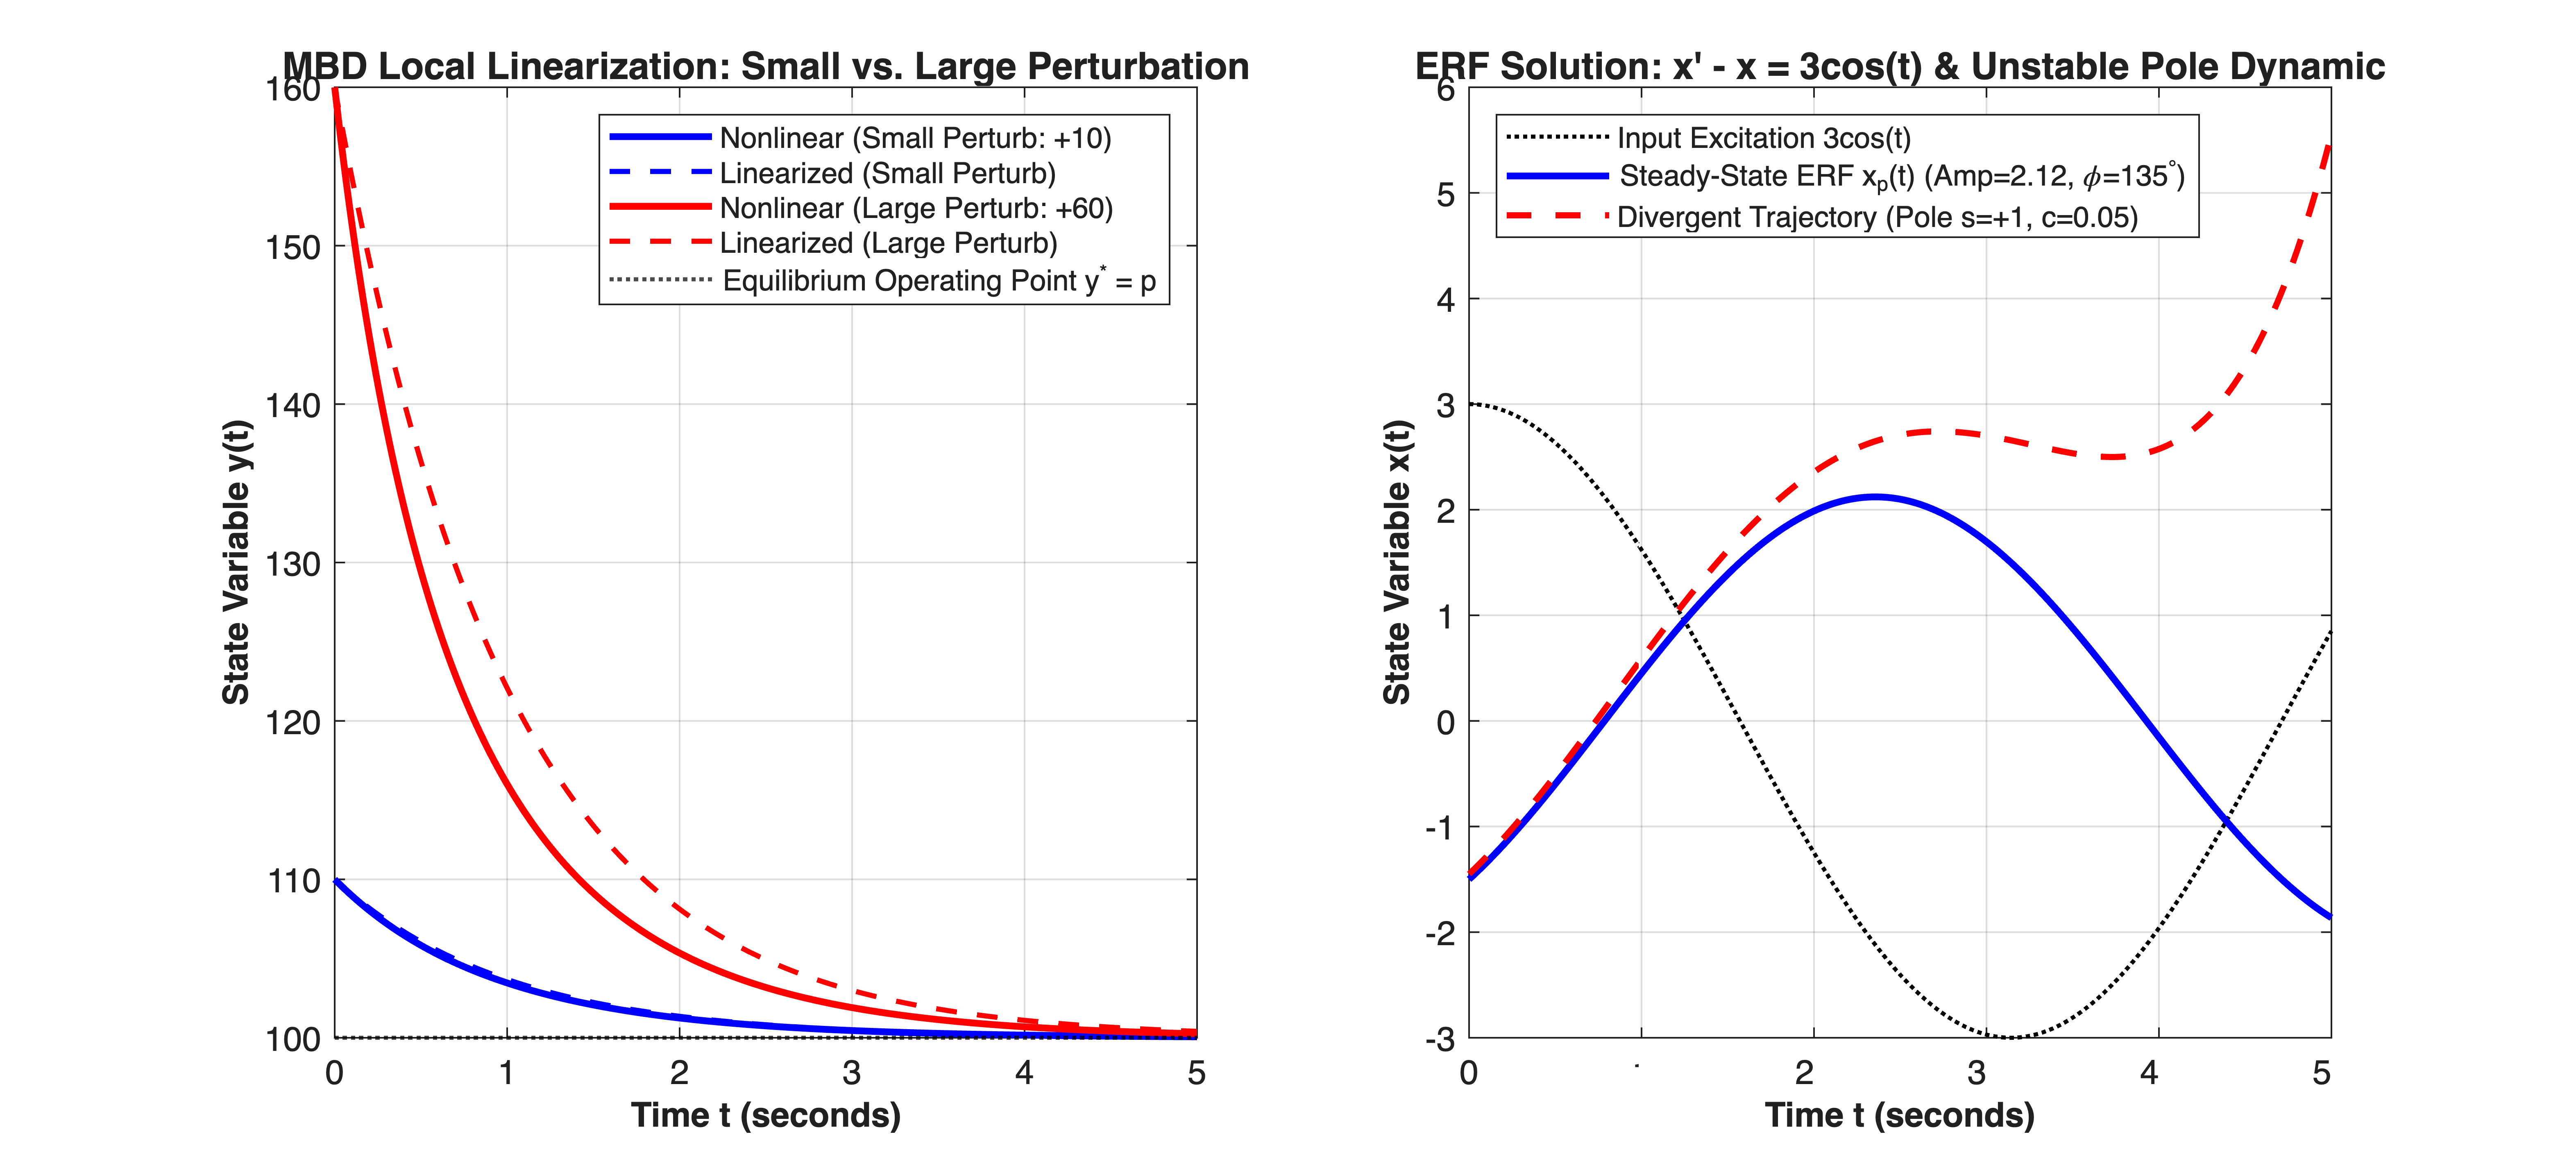

In [1]:
%% MIT 18.03 Lecture 9: Linear vs Nonlinear Dynamics, ERF & Local Linearization
% Description: Simulates three fundamental dynamics:
%              1) Nonlinear logistic equation vs. local Jacobian linearization around y = p.
%              2) Exponential Response Formula (ERF) for x' - x = 3*cos(t).
%              3) Finite-time blow-up of y' = y^2 with event detection guards.
%
% % Required Toolboxes:
% %   - Base MATLAB (Zero external dependency).
% % Optional Toolboxes:
% %   - Control System Toolbox (For tf/ss/linearize command equivalence).
%
% % MBD Concept Mapping: Demonstrates operating point trimming, small-signal linearization,
% %                      frequency response evaluation via ERF G(jw) = 1/P(jw), and nonlinear
% %                      stability boundary violations (Finite-Time Escape).


clear; clc; close all;


%% =========================================================================
%% Part 1: Local Linearization near Equilibrium (Section [1])
%% =========================================================================
k0 = 1.0;            % Intrinsic growth rate
p_cap = 100.0;       % Equilibrium carrying capacity (Operating point)
t_span = [0, 5];


% Nonlinear ODE: dy/dt = k0 * (1 - y/p) * y
ode_logistic = @(t, y) k0 * (1 - y / p_cap) * y;


% Linearized Perturbation ODE: du/dt = -k0 * u  -> y_lin(t) = p + u0 * exp(-k0*t)
u0_small = 10.0;     % Small perturbation: 10% of capacity
u0_large = 60.0;     % Large perturbation: 60% of capacity


opts = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);
t_eval = linspace(t_span(1), t_span(2), 300);


% Numerical simulation of nonlinear system
[~, y_nonlin_small] = ode45(ode_logistic, t_eval, p_cap + u0_small, opts);
[~, y_nonlin_large] = ode45(ode_logistic, t_eval, p_cap + u0_large, opts);


% Analytical evaluation of linearized system
y_lin_small = p_cap + u0_small * exp(-k0 * t_eval);
y_lin_large = p_cap + u0_large * exp(-k0 * t_eval);


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


% Subplot 1: Linearization Validation
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_eval, y_nonlin_small, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Nonlinear (Small Perturb: +10)');
plot(t_eval, y_lin_small, 'b--', 'LineWidth', 1.5, 'DisplayName', 'Linearized (Small Perturb)');
plot(t_eval, y_nonlin_large, 'r-', 'LineWidth', 2.0, 'DisplayName', 'Nonlinear (Large Perturb: +60)');
plot(t_eval, y_lin_large, 'r--', 'LineWidth', 1.5, 'DisplayName', 'Linearized (Large Perturb)');
yline(p_cap, 'k:', 'LineWidth', 1.2, 'DisplayName', 'Equilibrium Operating Point y^* = p');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Variable y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('MBD Local Linearization: Small vs. Large Perturbation', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 5]);
%% =========================================================================
%% Part 2: Exponential Response Formula (ERF) for x' - x = 3*cos(t) (Fixed)
%% =========================================================================
P_eval = -1 + 1i;
Z_p = 3 / P_eval;
A_polar = abs(Z_p);               % 3*sqrt(2)/2 ~ 2.1213
phi_polar = angle(Z_p);           % 3*pi/4 rad (135 deg)


% Steady-state particular solution handle
x_p_handle = @(t) real(Z_p * exp(1i * t));


% Evaluate numerical trajectories over time vector t_eval
c_pert = 0.05;
x_total_bounded  = x_p_handle(t_eval);                    % Periodic steady-state (c = 0)
x_total_unstable = x_p_handle(t_eval) + c_pert * exp(t_eval); % Divergent mode (c = 0.05)


% Subplot 2: ERF Sinusoidal Tracking & Unstable Pole Divergence
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_eval, 3 * cos(t_eval), 'k:', 'LineWidth', 1.2, ...
    'DisplayName', 'Input Excitation 3cos(t)');
plot(t_eval, x_total_bounded, 'b-', 'LineWidth', 2.0, ...
    'DisplayName', sprintf('Steady-State ERF x_p(t) (Amp=%.2f, \\phi=135^\\circ)', A_polar));
plot(t_eval, x_total_unstable, 'r--', 'LineWidth', 1.8, ...
    'DisplayName', 'Divergent Trajectory (Pole s=+1, c=0.05)');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Variable x(t)', 'FontSize', 10, 'FontWeight', 'bold');
title("ERF Solution: x' - x = 3cos(t) & Unstable Pole Dynamic", 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([0, 5]);

In [2]:
fprintf('=== MIT 18.03 Lecture 9 ERF & Linearization Diagnostics ===\n');

=== MIT 18.03 Lecture 9 ERF & Linearization Diagnostics ===

In [3]:
fprintf('Linearized Pole at Equilibrium p  : lambda = %.2f (Stable decay)\n', -k0);

Linearized Pole at Equilibrium p  : lambda = -1.00 (Stable decay)

In [4]:
fprintf('ERF Characteristic Operator P(i)  : %+.2f %+.2fi\n', real(P_eval), imag(P_eval));

ERF Characteristic Operator P(i)  : -1.00 +1.00i

In [5]:
fprintf('Complex Output Phasor Z_p         : %+.4f %+.4fi\n', real(Z_p), imag(Z_p));

Complex Output Phasor Z_p         : -1.5000 -1.5000i

In [6]:
fprintf('Steady-State Amplitude (A)        : %.4f (Analytical: 3*sqrt(2)/2 = 2.1213)\n', A_polar);

Steady-State Amplitude (A)        : 2.1213 (Analytical: 3*sqrt(2)/2 = 2.1213)

In [7]:
fprintf('Steady-State Phase Lag (phi)      : %.4f rad (%.1f deg)\n', phi_polar, phi_polar * 180/pi);

Steady-State Phase Lag (phi)      : -2.3562 rad (-135.0 deg)

In [8]:
fprintf('===========================================================\n');